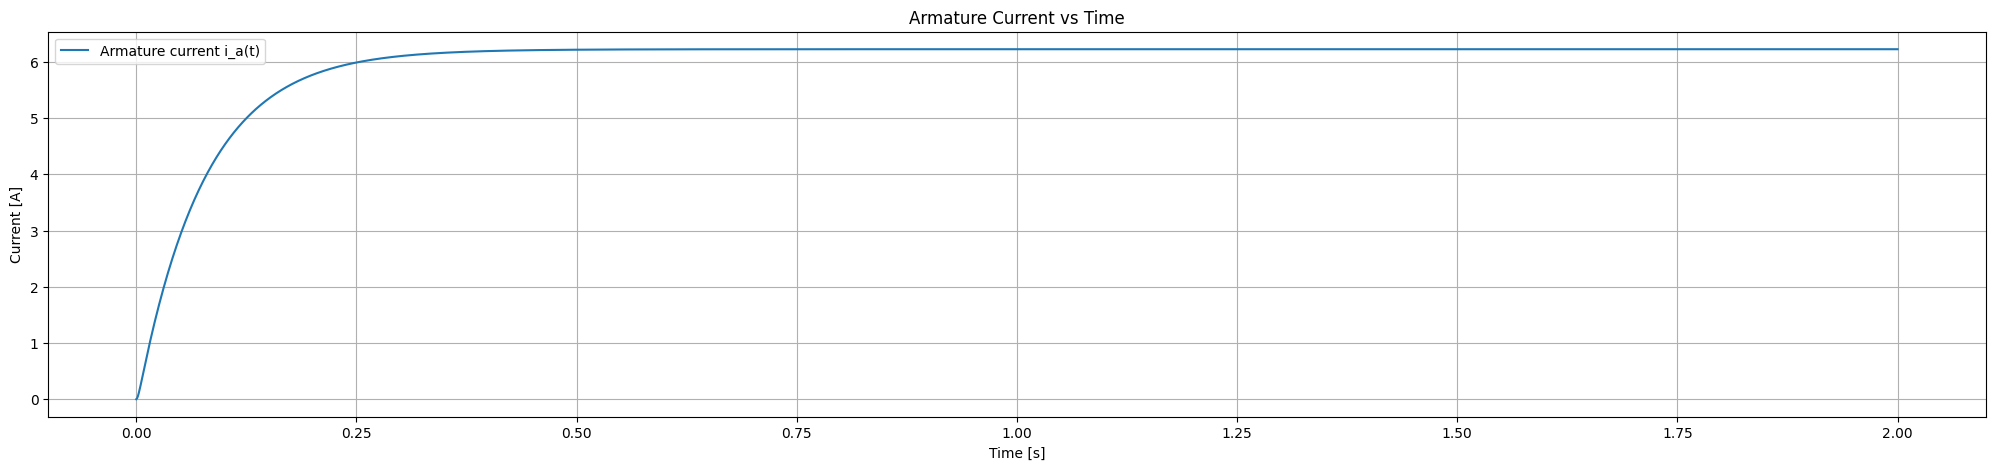

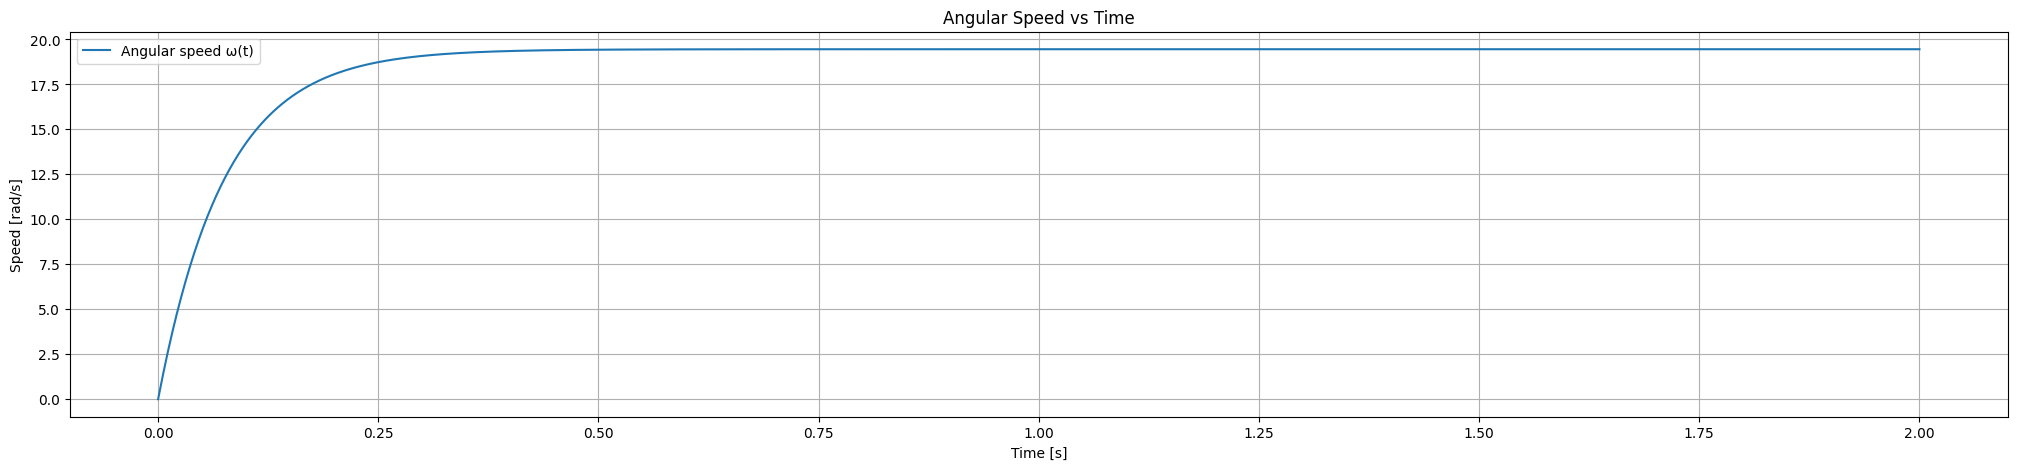

In [3]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

def build_A_resistive_load(Ra, La, J, B, K, RL):
    """
    v_t = RL * i_a -> absorbed into A matrix.
    dx/dt = A x + b*T_m   (single constant input)
    """
    A = np.array([[-(Ra + RL)/La,  K/La],
                  [      -K/J    , -B/J]], dtype=float)
    b = np.array([0.0, 1.0/J], dtype=float)  # multiplies T_m
    return A, b

def solve_with_resistive_load(params, RL, Tm, x0, t_span, t_eval=None, rtol=1e-7, atol=1e-9):
    """
    Solve with v_t = RL * i_a.
    """
    Ra, La, J, B, K = params["Ra"], params["La"], params["J"], params["B"], params["K"]
    A, b = build_A_resistive_load(Ra, La, J, B, K, RL)

    def rhs(t, x):
        # Only constant torque input
        dx = A.dot(x) + b * Tm
        return dx

    sol = solve_ivp(rhs, t_span, np.array(x0, dtype=float),
                    t_eval=t_eval, rtol=rtol, atol=atol)
    return sol  # sol.t, sol.y

# ---------- Example ----------

if __name__ == "__main__":
    params = {"Ra": 0.5, "La": 5e-3, "J": 0.02, "B": 1e-3, "K": 0.8}
    x0 = [0.0, 0.0]                 # i_a(0), omega(0)
    t_eval = np.linspace(0.0, 2, 2001)

    sol_rl = solve_with_resistive_load(params, RL=2.0, Tm=5.0,
                                       x0=x0, t_span=(0.0, 2), t_eval=t_eval)

    times = sol_rl.t
    ia = sol_rl.y[0]
    omega = sol_rl.y[1]

    # Plot current
    plt.figure(figsize=(25,5))
    plt.plot(times, ia, label="Armature current i_a(t)")
    plt.xlabel("Time [s]")
    plt.ylabel("Current [A]")
    plt.grid(True)
    plt.legend()
    plt.title("Armature Current vs Time")

    # Plot speed
    plt.figure(figsize=(25,5))
    plt.plot(times, omega, label="Angular speed ω(t)")
    plt.xlabel("Time [s]")
    plt.ylabel("Speed [rad/s]")
    plt.grid(True)
    plt.legend()
    plt.title("Angular Speed vs Time")

    plt.show()
